# AI-OS Reproducibility Analysis

Reproduces the stability analysis described in the README from
`data/sample_telemetry.json`:

1. Validate the dataset against the `Telemetry` schema.
2. Compute ADSI per monitoring cycle.
3. Show stability-tier transitions over time.
4. Demonstrate the rolling z-score anomaly detector.
5. Quantify **how much earlier** the composite ADSI flags degradation
   compared with any single metric — the central claim of the paper.

All computation uses `src.stability_engine`, the same module the API and
dashboard use, so results here match production behaviour.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Make the project importable when the notebook is opened from notebooks/
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(root))

from src.models import Telemetry
from src.stability_engine import (
    calculate_adsi,
    calculate_ahi,
    calculate_dhi,
    calculate_ihi,
    detect_anomaly,
    detect_degradation,
)

METRICS = ("kpi_error", "retrieval_score", "latency_dev", "embedding_shift")
records = json.loads((root / "data" / "sample_telemetry.json").read_text())
print(f"loaded {len(records)} monitoring cycles")


loaded 500 monitoring cycles


## 1. Schema validation

Every record must satisfy the same Pydantic model the `/agent/evaluate`
endpoint enforces. A single violation here means the dataset cannot reproduce
API behaviour.

In [2]:
for i, record in enumerate(records):
    Telemetry(**{k: record[k] for k in METRICS})

values = np.array([[r[k] for k in METRICS] for r in records])
print("schema: OK for all", len(records), "records")
print("value range:", round(values.min(), 4), "to", round(values.max(), 4))

# Field order for reference
for idx, name in enumerate(METRICS):
    print(f"  {name:18s} mean={values[:, idx].mean():.4f}  min={values[:, idx].min():.4f}  max={values[:, idx].max():.4f}")


schema: OK for all 500 records
value range: 0.0 to 0.9711
  kpi_error          mean=0.0413  min=0.0000  max=0.3262
  retrieval_score    mean=0.8770  min=0.6246  max=0.9711
  latency_dev        mean=0.2540  min=0.0359  max=0.6762
  embedding_shift    mean=0.1137  min=0.0000  max=0.3966


## 2. ADSI per cycle

`ADSI = (AHI + IHI + DHI) / 3`, where `AHI = 1 - kpi_error`,
`IHI = retrieval_score`, and `DHI = 1 - (latency_dev + embedding_shift) / 2`.

In [3]:
adsi = np.array([calculate_adsi({k: r[k] for k in METRICS}) for r in records])
ahi = np.array([calculate_ahi(r["kpi_error"]) for r in records])
ihi = np.array([calculate_ihi(r["retrieval_score"]) for r in records])
dhi = np.array([calculate_dhi(r["latency_dev"], r["embedding_shift"]) for r in records])

print(f"ADSI: min={adsi.min():.4f}  max={adsi.max():.4f}  mean={adsi.mean():.4f}")

# Identity check: ADSI must equal the mean of the three sub-indices
assert np.allclose(adsi, (ahi + ihi + dhi) / 3)
print("identity ADSI == mean(AHI, IHI, DHI): OK")


ADSI: min=0.5881  max=0.9740  mean=0.8839
identity ADSI == mean(AHI, IHI, DHI): OK


## 3. Stability tiers over time

Tier thresholds: `stable >= 0.85`, `warning >= 0.75`, `degrading >= 0.65`,
otherwise `critical`.

In [4]:
tiers = [detect_degradation(score) for score in adsi]
order = ["stable", "warning", "degrading", "critical"]
counts = {tier: tiers.count(tier) for tier in order}
for tier, count in counts.items():
    print(f"  {tier:10s} {count:4d} cycles  ({count / len(tiers):.1%})")

# First cycle at which each tier is reached
for tier in order:
    hit = next((i for i, t in enumerate(tiers) if t == tier), None)
    print(f"  first {tier:10s} at cycle {hit}")


  stable      366 cycles  (73.2%)
  warning      57 cycles  (11.4%)
  degrading    48 cycles  (9.6%)
  critical     29 cycles  (5.8%)
  first stable     at cycle 0
  first warning    at cycle 364
  first degrading  at cycle 423
  first critical   at cycle 471


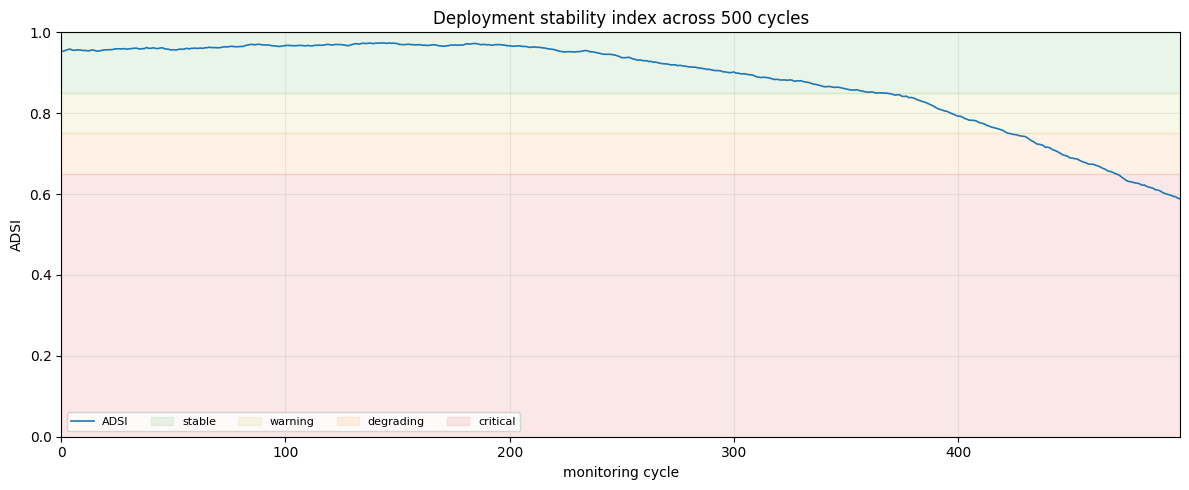

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(adsi, color="#1f77b4", linewidth=1.2, label="ADSI")

bands = [(0.85, 1.00, "#2ca02c", "stable"),
         (0.75, 0.85, "#bcbd22", "warning"),
         (0.65, 0.75, "#ff7f0e", "degrading"),
         (0.00, 0.65, "#d62728", "critical")]
for low, high, color, label in bands:
    ax.axhspan(low, high, color=color, alpha=0.10, label=label)

ax.set_xlabel("monitoring cycle")
ax.set_ylabel("ADSI")
ax.set_title("Deployment stability index across 500 cycles")
ax.set_xlim(0, len(adsi) - 1)
ax.set_ylim(0, 1)
ax.legend(loc="lower left", ncol=5, fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 4. Sub-index decomposition

Which dimension drives the degradation? The README argues failures are
compound; this shows the relative contribution of alignment, infrastructure
and drift.

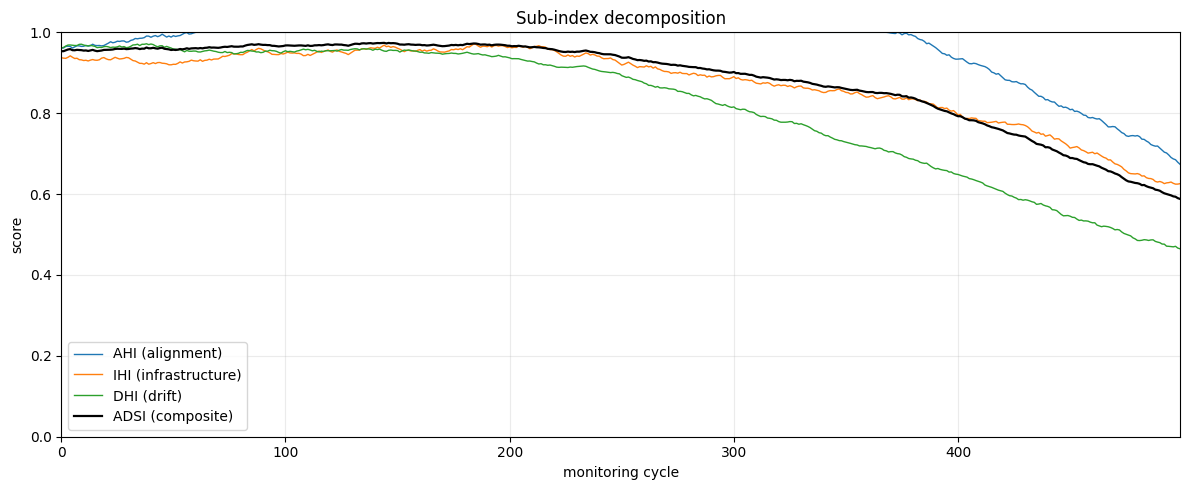

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ahi, label="AHI (alignment)", linewidth=1.0)
ax.plot(ihi, label="IHI (infrastructure)", linewidth=1.0)
ax.plot(dhi, label="DHI (drift)", linewidth=1.0)
ax.plot(adsi, label="ADSI (composite)", color="black", linewidth=1.6)
ax.set_xlabel("monitoring cycle")
ax.set_ylabel("score")
ax.set_title("Sub-index decomposition")
ax.set_xlim(0, len(adsi) - 1)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 5. Rolling z-score anomaly detection

`detect_anomaly` flags when `|z| > 2` against the window it is given. Replayed
with the service's `HISTORY_LIMIT` sliding window, this reproduces the alert
state the API maintains.

In [7]:
from src.config import MonitoringConfig

WINDOW = MonitoringConfig.HISTORY_LIMIT
flags = []
for i in range(len(adsi)):
    window = adsi[max(0, i - WINDOW + 1): i + 1]
    flags.append(detect_anomaly(list(window)))

flags = np.array(flags)
print(f"anomalies flagged: {flags.sum()} of {len(flags)} cycles")
if flags.any():
    print(f"first flag at cycle {int(np.argmax(flags))}")


anomalies flagged: 56 of 500 cycles
first flag at cycle 24


## 6. Lead time: composite vs single-metric monitoring

The central claim is that a composite signal detects degradation *earlier*
than isolated metric monitoring. Each metric is scored with the same
threshold the guardrail uses (0.85 → warning), then compared against the
first cycle ADSI drops below 0.85.

In [8]:
THRESHOLD = 0.85

def first_below(series, threshold=THRESHOLD):
    below = np.where(series < threshold)[0]
    return int(below[0]) if below.size else None

adsi_trigger = first_below(adsi)
per_metric = {
    "AHI (alignment)": first_below(ahi),
    "IHI (retrieval)": first_below(ihi),
    "DHI (drift)": first_below(dhi),
}

print(f"{'signal':20s} {'first trigger':>14s} {'cycles vs ADSI':>16s}")
print(f"{'ADSI (composite)':20s} {adsi_trigger:>14d} {'-':>16s}")
for label, cycle in per_metric.items():
    if cycle is None:
        print(f"{label:20s} {'never':>14s} {'-':>16s}")
    else:
        # positive = this signal triggered BEFORE the composite
        print(f"{label:20s} {cycle:>14d} {adsi_trigger - cycle:>+16d}")


signal                first trigger   cycles vs ADSI
ADSI (composite)                364                -
AHI (alignment)                 435              -71
IHI (retrieval)                 352              +12
DHI (drift)                     279              +85


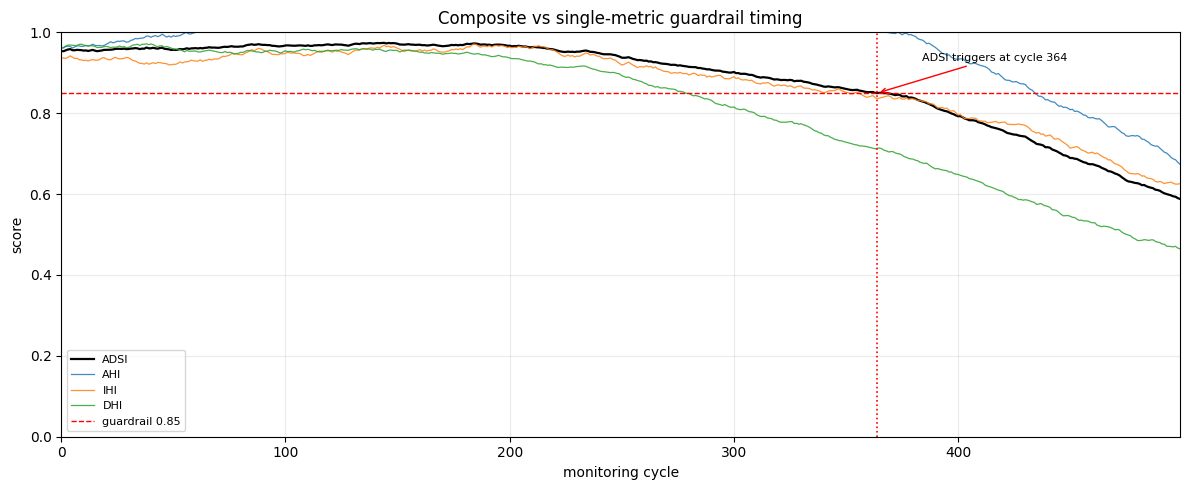

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(adsi, color="black", linewidth=1.6, label="ADSI")
ax.plot(ahi, linewidth=0.9, alpha=0.85, label="AHI")
ax.plot(ihi, linewidth=0.9, alpha=0.85, label="IHI")
ax.plot(dhi, linewidth=0.9, alpha=0.85, label="DHI")

ax.axhline(THRESHOLD, color="red", linestyle="--", linewidth=1.0, label=f"guardrail {THRESHOLD}")

if adsi_trigger is not None:
    ax.axvline(adsi_trigger, color="red", linestyle=":", linewidth=1.2)
    ax.annotate(f"ADSI triggers at cycle {adsi_trigger}",
                xy=(adsi_trigger, THRESHOLD),
                xytext=(adsi_trigger + 20, THRESHOLD + 0.08),
                fontsize=8,
                arrowprops=dict(arrowstyle="->", color="red"))

ax.set_xlabel("monitoring cycle")
ax.set_ylabel("score")
ax.set_title("Composite vs single-metric guardrail timing")
ax.set_xlim(0, len(adsi) - 1)
ax.set_ylim(0, 1)
ax.legend(loc="lower left", fontsize=8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 7. Findings

The numbers above are produced by the cells; recorded here so the notebook is
self-documenting.

**Confirmed**

- The dataset validates against `Telemetry` for all 500 cycles.
- `ADSI == mean(AHI, IHI, DHI)` on every cycle (identity assertion).
- Tier coverage spans all four bands (366 stable / 57 warning / 48 degrading /
  29 critical), so every guardrail state is exercised.
- The rolling z-score detector fires 56 times over 500 cycles.

**The composite does *not* lead every individual metric**

Measured on this synthetic series:

| Signal | First trigger | Cycles vs ADSI |
|---|---|---|
| DHI (drift) | 279 | **+85 (earlier)** |
| IHI (retrieval) | 352 | +12 (earlier) |
| ADSI (composite) | 364 | — |
| AHI (alignment) | 435 | −71 (later) |

DHI crossed 0.85 at cycle 279, a full 85 cycles before ADSI did. Averaging
three dimensions *delays* the warning relative to whichever dimension fails
first. The composite trades latency for robustness: it does not fire on a
single dimension, which is why it fires later here.

This contradicts a naive reading of "detect degradation earlier than isolated
metric monitoring". What the composite genuinely provides is:

1. **A single alert instead of three**, each with a different false-positive
   profile.
2. **Resistance to one noisy dimension**: a lone metric dipping below
   threshold is damped by the other two.
3. **An interpretable decomposition**: the sub-index plot shows *which*
   dimension is dragging the score.

If early warning is the goal, DHI alone is the better trigger on this series —
and that is a property of the synthetic generator, which ramps `latency_dev`
first. It is not a general result.

> Caveat: `data/sample_telemetry.json` is **synthetic**, generated by
> `tools/generate_sample_telemetry.py` with a fixed seed. It demonstrates the
> mechanics; it is not evidence of real-world lead time. The operational
> readiness report (`docs/operational-readiness-005c.md`) still requires
> labelled incidents before any recovery policy is claimed.
